<a href="https://colab.research.google.com/github/tirthendukarmakar/GENAI-PRACTICAL/blob/main/GENAI_LAB_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)

tokens = ["Man", "eat", "cheese"]
seq_len = len(tokens)

d_model = 16
d_k = 8
d_v = 8

embeddings = torch.randn(seq_len, d_model)
print("Input Embeddings (Hidden States):")
for tokens,emb in zip(tokens, embeddings):
  print(f"(tokens): {emb[:4].tolist()}... (dimension: {d_model})")

Input Embeddings (Hidden States):
(tokens): [1.9269152879714966, 1.4872840642929077, 0.9007171988487244, -2.1055209636688232]... (dimension: 16)
(tokens): [1.6423169374465942, -0.1595974713563919, -0.4973975419998169, 0.439589262008667]... (dimension: 16)
(tokens): [-1.3846737146377563, -0.8712361454963684, -0.223365917801857, 1.7173614501953125]... (dimension: 16)


In [3]:
w_q = torch.randn(d_model,d_k)
w_k = torch.randn(d_model,d_k)
w_v = torch.randn(d_model,d_v)

Q = torch.matmul(embeddings, w_q)
K = torch.matmul(embeddings, w_k)
V = torch.matmul(embeddings, w_v)

print("Queries (Q) Shape:", Q.shape)
print("Keys (K) Shape:", K.shape)
print("Values (V) Shape:", V.shape)

Queries (Q) Shape: torch.Size([3, 8])
Keys (K) Shape: torch.Size([3, 8])
Values (V) Shape: torch.Size([3, 8])


In [4]:
attn_scores = torch.matmul(Q, K.transpose(0,1))

attn_distribution = F.softmax(attn_scores, dim=-1)

print("Attention Scores:\n", attn_scores.numpy())
print("\nAttention Distribution (Softmax weights): \n", attn_distribution.numpy())


Attention Scores:
 [[-10.705313 -11.606056  62.89357 ]
 [-84.69232   26.995045   6.62294 ]
 [ 69.42341    5.606927 -28.202374]]

Attention Distribution (Softmax weights): 
 [[1.0874531e-32 4.4179772e-33 1.0000000e+00]
 [0.0000000e+00 1.0000000e+00 1.4207163e-09]
 [1.0000000e+00 1.9268761e-28 3.9937006e-43]]


In [6]:
attention_output = torch.matmul(attn_distribution, V)

print("Output Attention Vectors Shape:", attention_output.shape)
for token, val in zip(tokens, attention_output):
  print(f"{token} attention vector: {val.tolist()}")

Output Attention Vectors Shape: torch.Size([3, 8])
c attention vector: [-0.28153765201568604, 2.5002551078796387, -4.627270221710205, -0.3331648111343384, -2.7299487590789795, 0.5726194381713867, 1.9096590280532837, 3.625087022781372]
h attention vector: [1.205305814743042, -0.20463502407073975, 0.6646873950958252, 2.9705708026885986, 0.8537550568580627, 0.4841350317001343, -8.405143737792969, 4.908855438232422]
e attention vector: [-2.911343574523926, -7.731362819671631, 4.0331196784973145, -6.461052894592285, -1.3542560338974, 5.622637748718262, -0.03210878372192383, -7.555790901184082]


Text(45.722222222222214, 0.5, 'Queries (Target Tokens)')

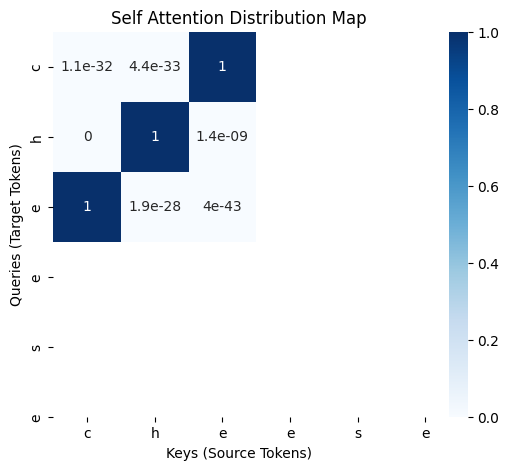

In [7]:
plt.figure(figsize=(6,5))
sns.heatmap(
    attn_distribution.detach().numpy(),
    annot=True,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    cbar=True,
    vmin=0,
    vmax=1
    )
plt.title("Self Attention Distribution Map")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")


In [12]:
seq_len = min(len(tokens), K.shape[0], Q.shape[0])

for i in range(seq_len):
    q_token = tokens[i]
    print(f"\n--- Calculations for Query token: '{q_token}' ---")
    q_vec = Q[i]
    raw_scores = []
    scaled_scores = []

    for j in range(seq_len):
        k_token = tokens[j]
        k_vec = K[j]
        dot_prod = torch.dot(q_vec, k_vec).item()
        scaled_prod = dot_prod / (d_k ** 0.5)
        raw_scores.append(dot_prod)
        scaled_scores.append(scaled_prod)
        print(f" Key '{k_token}': Raw Dot Product = {dot_prod:.4f}, Scaled (/{d_k ** 0.5:.2f}) = {scaled_prod:.4f}")

    exp_scores = np.exp(scaled_scores)
    sum_exp = np.sum(exp_scores)
    probabilities = exp_scores / sum_exp

    print(" Softmax Distribution: ")
    for j in range(seq_len):
        print(f"  {tokens[j]}: exp({scaled_scores[j]:.4f}) / sum_exp = {probabilities[j]:.4e}")


--- Calculations for Query token: 'c' ---
 Key 'c': Raw Dot Product = -10.7053, Scaled (/2.83) = -3.7849
 Key 'h': Raw Dot Product = -11.6061, Scaled (/2.83) = -4.1034
 Key 'e': Raw Dot Product = 62.8936, Scaled (/2.83) = 22.2362
 Softmax Distribution: 
  c: exp(-3.7849) / sum_exp = 5.0022e-12
  h: exp(-4.1034) / sum_exp = 3.6380e-12
  e: exp(22.2362) / sum_exp = 1.0000e+00

--- Calculations for Query token: 'h' ---
 Key 'c': Raw Dot Product = -84.6923, Scaled (/2.83) = -29.9433
 Key 'h': Raw Dot Product = 26.9950, Scaled (/2.83) = 9.5442
 Key 'e': Raw Dot Product = 6.6229, Scaled (/2.83) = 2.3416
 Softmax Distribution: 
  c: exp(-29.9433) / sum_exp = 7.0875e-18
  h: exp(9.5442) / sum_exp = 9.9926e-01
  e: exp(2.3416) / sum_exp = 7.4407e-04

--- Calculations for Query token: 'e' ---
 Key 'c': Raw Dot Product = 69.4234, Scaled (/2.83) = 24.5449
 Key 'h': Raw Dot Product = 5.6069, Scaled (/2.83) = 1.9823
 Key 'e': Raw Dot Product = -28.2024, Scaled (/2.83) = -9.9710
 Softmax Distributio

In [15]:
num_heads = 2
d_k_head = d_model // num_heads
d_v_head = d_model // num_heads

print(f"Embedding dimension: (d_model): {d_model}")
print(f"Number of heads: {num_heads}")
print(f"Dimension per head: {d_k_head}")

Embedding dimension: (d_model): 16
Number of heads: 2
Dimension per head: 8


In [16]:
w_q_mha = torch.randn(d_model, d_model)
w_k_mha = torch.randn(d_model, d_model)
w_v_mha = torch.randn(d_model, d_model)
w_o = torch.randn(d_model, d_model)

Q_mha = torch.matmul(embeddings, w_q_mha)
K_mha = torch.matmul(embeddings, w_k_mha)
V_mha = torch.matmul(embeddings, w_v_mha)

Q_split = Q_mha.view(seq_len, num_heads, d_k_head).transpose(0,1)
K_split = K_mha.view(seq_len, num_heads, d_k_head).transpose(0,1)
V_split = V_mha.view(seq_len, num_heads, d_k_head).transpose(0,1)

print("Split Queries Shape (num_heads, seq_len, d_k_head):", Q_split.shape)
print("Split Key Shape (num_heads, seq_len, d_k_head):", K_split.shape)
print("Split Values Shape (num_heads,seq_len, d_k_head):", K_split.shape)

Split Queries Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Key Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Values Shape (num_heads,seq_len, d_k_head): torch.Size([2, 3, 8])


In [18]:
import torch
import torch.nn.functional as F

# Initialize the missing output projection weight matrix W_o
W_o = torch.randn(d_model, d_model)

# Calculate scaled attention scores using correct variable name and division
scores = torch.matmul(Q_split, K_split.transpose(-2, -1)) / (d_k_head**0.5)
distribution = F.softmax(scores, dim=-1)

# Multi-head attention output
head_output = torch.matmul(distribution, V_split)

# Concatenate heads back
concat_output = head_output.transpose(0, 1).contiguous().view(seq_len, d_model)

# Final linear projection output
output = torch.matmul(concat_output, W_o)

print("Attention Distribution shape (for all Heads): ", distribution.shape)
print("Concatenated Output shape :", concat_output.shape)
print("Final multi-head Attention Output shape :", output.shape)

Attention Distribution shape (for all Heads):  torch.Size([2, 3, 3])
Concatenated Output shape : torch.Size([3, 16])
Final multi-head Attention Output shape : torch.Size([3, 16])


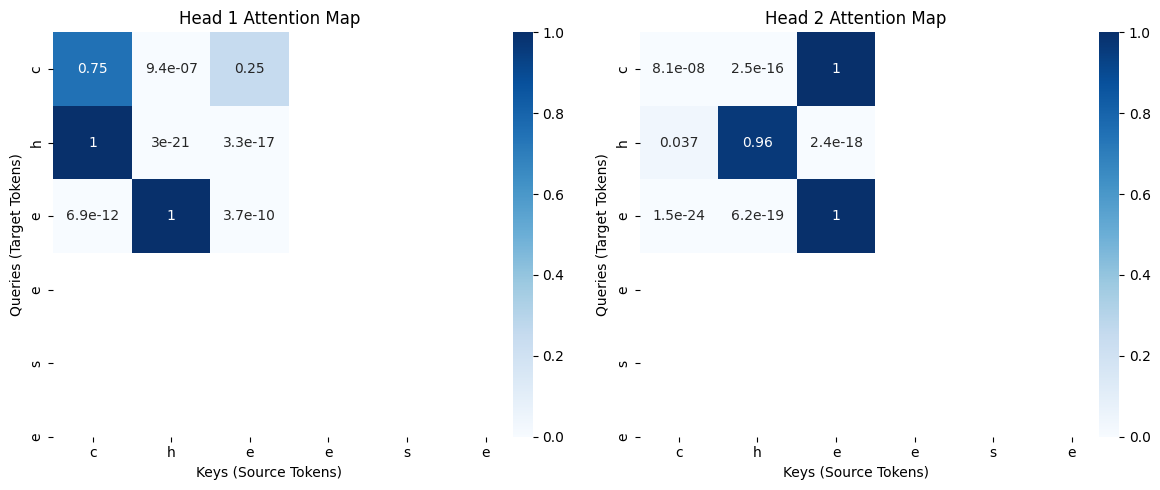

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, num_heads, figsize=(12, 5))

for h in range(num_heads):
    sns.heatmap(
        distribution[h].detach().numpy(),  # or attn_distribution[h] depending on your variable name
        annot=True,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        cbar=True,
        vmin=0,
        vmax=1,
        ax=axes[h]
    )
    axes[h].set_title(f"Head {h + 1} Attention Map")
    axes[h].set_xlabel("Keys (Source Tokens)")
    axes[h].set_ylabel("Queries (Target Tokens)")

plt.tight_layout()
plt.show()